# RouteRanker – Module 6: Model Inference and Route Optimization
**Goal:** apply the *already trained* Module-5 models to unseen routes, find routes that may need a closer look, turn that into possible merge / split / frequency suggestions, and compare the current network with a **simulated** one.

**Rules followed:** no passenger counts, demand or crowding values are invented (GTFS has none); no route is called inefficient from one feature or one cluster; suggestions are *candidates to verify*; the original data is never changed – simulated results are stored separately.

| kind | examples | status |
|---|---|---|
| Actual data | trips, stops, headway ... from the GTFS schedule | scheduled, not passenger data |
| Model predictions | KMeans cluster, DBSCAN label, closest known feed | outputs of the Module-5 models, not facts |
| Estimates | route length, evidence flags, length after a merge | derived with stated rules |
| Simulated results | everything in `data/simulated/` and the comparison tables | what-if under stated assumptions |

In [1]:
import os, sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings("ignore")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src import inference as inf, optimization as opt, preprocessing as pp
pd.set_option("display.max_columns", 40, "display.width", 200)

## Step 1 – Load the trained models and the preprocessing objects
Inference means: **no training again** – the saved objects are loaded and applied.

In [2]:
models = inf.load_models()          # KMeans, DBSCAN, XGBoost, Random Forest + the preprocessor fitted in Module 4
{k: type(v).__name__ for k, v in models.items()}

{'prep': 'RoutePreprocessor',
 'kmeans': 'KMeans',
 'dbscan': 'DBSCAN',
 'xgb': 'XGBClassifier',
 'rf': 'RandomForestClassifier'}

## Step 2 – Prepare new / unseen data
`unseen_routes.csv` holds the **validation routes** (held out in Module 4, never used to fit the models) and the routes of **Hyderabad**, a feed that was excluded from training. Any table with the Module-2 route-feature columns can be used instead (for example a new city produced by `run_module2.py`).

In [3]:
unseen = pd.read_csv("data/inference/unseen_routes.csv", dtype={"route_id": str, "route_name": str})
print(unseen.shape); print(unseen.data_role.value_counts().to_dict())
inf.check_columns(unseen); print("all required feature columns are present")
unseen[["city", "route_id", "route_name", "n_trips", "n_unique_stops", "length_km", "service_span_h", "data_role"]].head()

(3631, 49)
{'validation (unseen routes)': 2600, 'unseen feed (not in Module-4 training set)': 1031}
all required feature columns are present


,city,route_id,route_name,n_trips,n_unique_stops,length_km,service_span_h,data_role
0,ahmedabad,AMC_1807,105,108,40,63.748132,17.083333,validation (unseen routes)
1,ahmedabad,AMC_1808,105,108,39,63.705158,17.083333,validation (unseen routes)
2,ahmedabad,AMC_1811,107,6,91,78.537876,13.333333,validation (unseen routes)
3,ahmedabad,AMC_1861,123,12,51,32.919520,14.666667,validation (unseen routes)
4,ahmedabad,AMC_1862,123,12,53,33.013401,12.000000,validation (unseen routes)


## Step 3 – Apply the *same* preprocessing (no new scaler or encoder)
The fitted preprocessor carries the training medians, skew decisions, means/standard deviations and category lists.

In [4]:
prep = models["prep"]
print("scaler mean of n_trips learned from TRAINING routes:", round(float(prep.scaler.mean_[prep.num.index("n_trips")]), 4))
d, X = inf.prepare_new(unseen, prep)
print("model-ready table:", X.shape, "| missing values:", int(X.isna().sum().sum()))
X.head(3)

scaler mean of n_trips learned from TRAINING routes: 2.1466
model-ready table: (3631, 25) | missing values: 0


,median_headway_min_was_missing,avg_speed_kmh_was_missing,n_trips,n_unique_stops,median_stops_per_trip,length_km,service_span_h,n_active_hours,trips_per_active_hour,median_headway_min,avg_trip_duration_min,stops_per_km,avg_speed_kmh,max_stop_overlap,mean_routes_per_stop,share_morning,share_afternoon,share_evening,length_method__shapes.txt,length_method__stop coordinates (shape failed sanity check),"length_method__stop coordinates (straight-line, approximate)",peak_period__afternoon,peak_period__evening,peak_period__morning,peak_period__night
0,0,0,2.168072,0.307309,0.424358,1.750090,1.267590,1.891722,2.777000,-1.518008,0.400811,-1.460605,3.326048,-2.006924,-0.721988,-0.330934,0.192189,0.323775,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,0,0,2.168072,0.278043,0.370115,1.749182,1.267590,1.891722,2.777000,-1.518008,0.318615,-1.475841,3.554486,-1.997238,-0.847428,-0.049877,0.229240,0.237853,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,0,0,-0.171002,1.265239,3.244994,2.031407,0.666384,-0.165649,-0.677936,1.058422,1.199740,-0.930744,2.189404,1.095261,-0.599207,0.231179,0.338836,-0.073393,0.0,0.0,1.0,0.0,0.0,1.0,0.0


**Consistency check:** re-applying the saved preprocessor to the raw validation routes must reproduce the Module-4 validation table exactly.

In [5]:
va = pd.read_csv("data/processed/module4/validation_preprocessed.csv", dtype={"route_id": str, "route_name": str})
v = unseen[unseen.data_role.str.startswith("validation")].merge(va[["city", "route_id"]], on=["city", "route_id"])
_, Xv = inf.prepare_new(v, prep)
saved = va.set_index(["city", "route_id"]).loc[list(zip(v.city, v.route_id)), Xv.columns]
print("largest difference to the stored validation table:", float(np.abs(Xv.values - saved.values).max()))

largest difference to the stored validation table: 1.582067810090848e-15


## Step 4 – Run inference
* **KMeans:** nearest centroid. * **DBSCAN:** has no `predict`; a new route takes the cluster of its **nearest core point if that point is within `eps`**, otherwise it is noise (-1). * **XGBoost:** the known feed whose schedule features the route resembles most (a diagnostic, not a route-quality label).

In [6]:
prof = pd.read_csv("reports/tables/module5_kmeans_cluster_profile.csv", index_col=0)
names = inf.name_clusters(prof)
db = models["dbscan"]; print("DBSCAN eps =", db.eps, "| core points stored:", len(db.components_))
d, X, out = inf.run_inference(unseen, models, names); out["data_role"] = unseen.data_role.values
display(pd.DataFrame({"cluster": list(names), "description (scheduled service only)": list(names.values())}))
out.head()

DBSCAN eps = 3.0 | core points stored: 10157


,cluster,description (scheduled service only)
0,0,"mixed-day, mid-range service"
1,1,very few scheduled trips; mostly evening depar...
2,2,relatively many scheduled trips
3,3,very few scheduled trips; mostly afternoon dep...
4,4,very few scheduled trips; very short route (fe...
5,5,relatively many scheduled trips
6,6,very few scheduled trips; mostly morning depar...


,city,route_id,route_name,kmeans_cluster,kmeans_cluster_description,dist_to_centroid,dbscan_label,dist_to_nearest_core,closest_known_feed,closest_feed_probability,data_role
0,ahmedabad,AMC_1807,105,5,relatively many scheduled trips,5.327,0,2.527,ahmedabad,0.991,validation (unseen routes)
1,ahmedabad,AMC_1808,105,5,relatively many scheduled trips,5.374,0,2.208,ahmedabad,0.990,validation (unseen routes)
2,ahmedabad,AMC_1811,107,0,"mixed-day, mid-range service",4.362,0,0.065,ahmedabad,0.940,validation (unseen routes)
3,ahmedabad,AMC_1861,123,0,"mixed-day, mid-range service",2.126,0,1.088,chennai,0.944,validation (unseen routes)
4,ahmedabad,AMC_1862,123,0,"mixed-day, mid-range service",2.047,0,0.928,chennai,0.908,validation (unseen routes)


Cluster numbers are **not** rankings; a description such as 'very few scheduled trips' is a statement about the timetable, not about performance.

## Step 5 – Analyse the results

In [7]:
by_role = out.groupby("data_role").agg(routes=("route_id", "size"), dbscan_noise_pct=("dbscan_label", lambda s: round(100 * (s == -1).mean(), 1)),
                                       mean_distance_to_centroid=("dist_to_centroid", "mean"), mean_closest_feed_probability=("closest_feed_probability", "mean")).round(2)
by_role

,routes,dbscan_noise_pct,mean_distance_to_centroid,mean_closest_feed_probability
data_role,,,,
unseen feed (not in Module-4 training set),1031,81.7,5.08,0.87
validation (unseen routes),2600,1.0,2.94,0.96


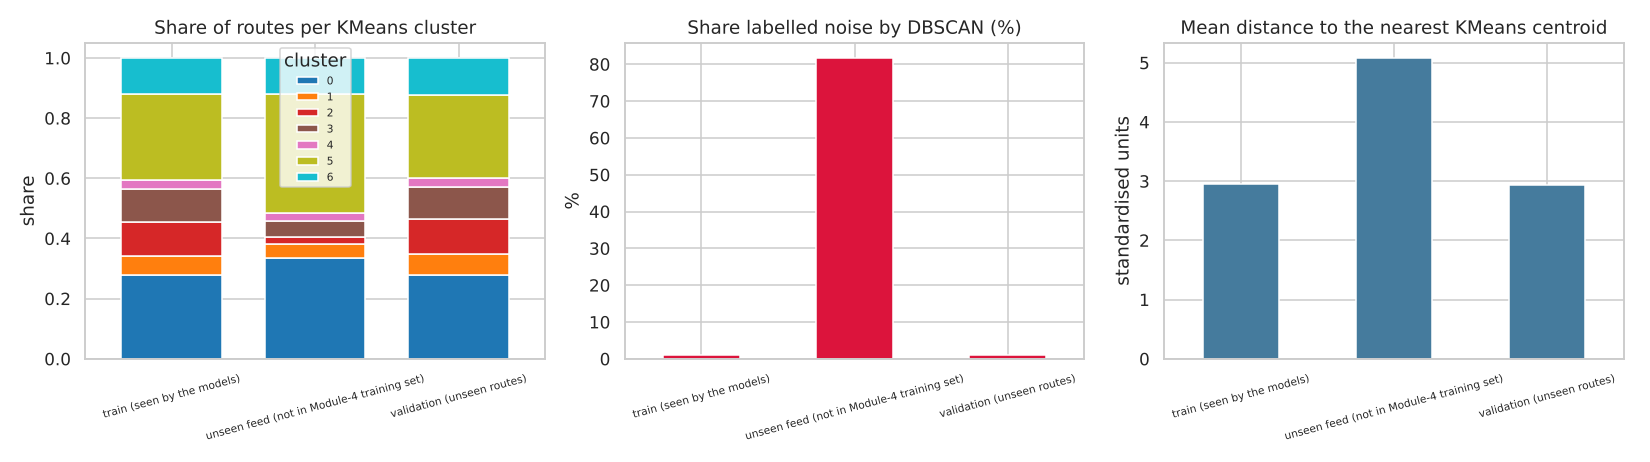

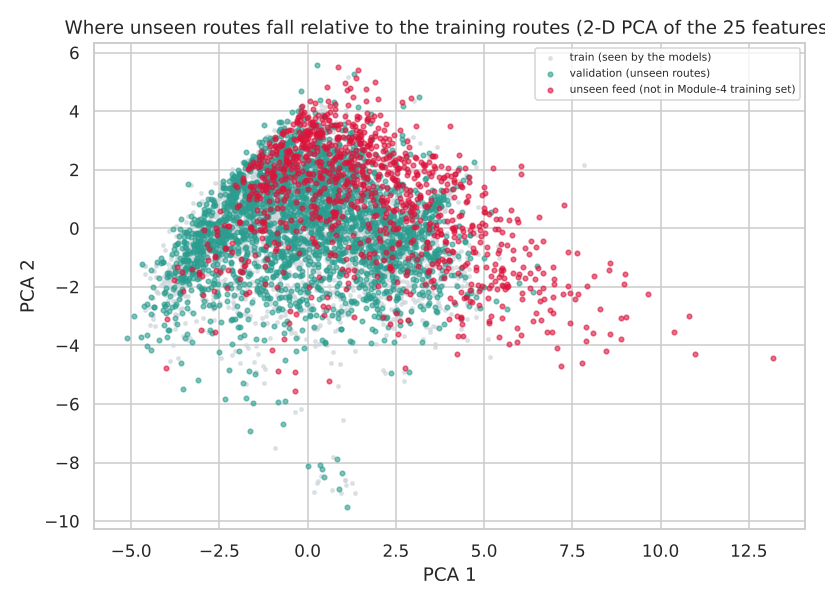

In [8]:
display(Image("reports/figures/module6/m6_01_inference_by_data_role.png"))
display(Image("reports/figures/module6/m6_02_pca_unseen_routes.png"))

**Reading:** the held-out validation routes behave like training routes (same noise share, same distance to the centroids), so the models generalise to routes they did not see. The **unseen Hyderabad feed does not fit**: most of its routes are DBSCAN noise and far from every centroid. This supports the earlier finding that this feed is **not comparable** with the others (its 'trips' look like whole vehicle duties) – it is **not** evidence that its routes are wrong or inefficient, and its routes are not used for suggestions.

## Step 6 – Which routes may need further investigation?
A route is listed only when **at least two independent pieces of evidence** agree – never one feature or one cluster alone. (Hyderabad is excluded.)

In [9]:
raw = pp.load_features()
prof_sparse = list(prof.index[prof.n_trips <= 2])
dd = pd.concat([d.reset_index(drop=True), out[["kmeans_cluster", "dbscan_label"]].reset_index(drop=True)], axis=1)
allr = pp.add_derived(raw); _, Xall = inf.prepare_new(raw, prep)
full = pd.concat([allr.reset_index(drop=True), pd.DataFrame({"kmeans_cluster": models["kmeans"].predict(Xall.values), "dbscan_label": inf.dbscan_infer(db, Xall.values)[0]})], axis=1)
comp = full[~full.city.isin(pp.EXCLUDE_FEEDS)].reset_index(drop=True)
ev, flags = opt.evidence_flags(comp, prof_sparse)
print(pd.crosstab(ev.city, ev.n_evidence))
print("routes with an impossible scheduled speed (check the data first):", int(ev.data_check_first.sum()))

n_evidence     0     1     2    3  4
city                                
ahmedabad    444   276   203   47  2
bengaluru   1005  1719  1440  243  9
chennai     1225  1268   977  464  0
delhi       1776   664   428   96  0
kochi        270   195     0    0  0
pune         210    75    28    2  0
routes with an impossible scheduled speed (check the data first): 121


In [10]:
ev[ev.n_evidence >= 3][["city", "route_name", "n_evidence", "n_trips", "n_unique_stops", "length_km", "max_stop_overlap"]].head(8)

,city,route_name,n_evidence,n_trips,n_unique_stops,length_km,max_stop_overlap
13,ahmedabad,109,3,1,24,10.237469,0.807692
23,ahmedabad,117,3,1,21,6.156823,1.000000
32,ahmedabad,123,3,3,37,27.950142,1.000000
198,ahmedabad,31,3,3,33,11.006450,0.857143
245,ahmedabad,40/2,3,1,39,53.655493,0.353659
272,ahmedabad,51Ri,3,1,37,12.341273,1.000000
274,ahmedabad,51sh,3,3,48,17.346495,0.960000
299,ahmedabad,64/2,3,3,36,10.094496,0.805556


**An illustration of the idea in the task description** – three real Pune routes of similar length but different scheduled trips. Different trip counts are a reason to *look*, not proof of inefficiency; passenger demand, vehicle capacity, coverage and operations would be needed.

In [11]:
p = comp[(comp.city == "pune") & comp.length_km.between(15, 19) & (comp.n_trips > 0)].sort_values("n_trips")
pd.concat([p.head(1), p.iloc[[len(p) // 2]], p.tail(1)])[["route_name", "n_trips", "n_unique_stops", "length_km"]]

,route_name,n_trips,n_unique_stops,length_km
12757,111M,4,74,17.308033
12972,367,25,98,18.992410
12759,114,116,82,15.256618


## Step 7 – Optimisation suggestions (candidates to verify)
### A. Merging  – `stop sets >= 80% similar, different line names, the lighter route has few trips, similar length`

In [12]:
mg = opt.merge_candidates(ev); print(len(mg), "candidate merges:", mg.groupby("city").size().to_dict())
mg.head(6)[["city", "absorbed_route", "target_route", "stop_overlap_jaccard", "trips_absorbed", "trips_target", "length_absorbed_km", "length_target_km"]]

949 candidate merges: {'ahmedabad': 54, 'bengaluru': 301, 'chennai': 489, 'delhi': 98, 'pune': 7}


,city,absorbed_route,target_route,stop_overlap_jaccard,trips_absorbed,trips_target,length_absorbed_km,length_target_km
0,ahmedabad,117,28,1.0,1,16,6.2,6.2
1,ahmedabad,51Ri,51sh,1.0,1,18,12.3,12.3
2,ahmedabad,37sh,123,1.0,1,10,5.1,5.1
3,ahmedabad,51sh,51T,1.0,1,4,7.8,7.8
4,ahmedabad,51Ri,51sh,1.0,1,18,12.6,12.6
5,ahmedabad,16E,17E,1.0,2,8,5.3,5.3


Shared stops give the **geographical connectivity**; the route is only a *candidate*. Before merging: passenger demand, capacity, travel time, coverage of the unshared stops, and whether the routes serve different purposes (express vs local) must be checked.

### B. Splitting – long (>= 40 km and in the top 10% of its city) and complex (>= 30 stops)

In [13]:
sp = opt.split_candidates(ev); print(len(sp), "candidate splits:", sp.groupby("city").size().to_dict())
sp.sort_values("length_km", ascending=False).head(6)

838 candidate splits: {'ahmedabad': 84, 'bengaluru': 379, 'chennai': 158, 'delhi': 160, 'kochi': 25, 'pune': 32}


,city,route_id,route,length_km,length_method,stops,trips,service_span_h
397,bengaluru,8433,V-DIVYA DARSHANA-1A,164.8,shapes.txt,38,1,0.0
39,ahmedabad,AMC_2718,66/3sh,157.4,"stop coordinates (straight-line, approximate)",90,1,0.0
255,bengaluru,3594,317-BH,138.0,shapes.txt,122,2,1.9
32,ahmedabad,AMC_2606,52,136.9,"stop coordinates (straight-line, approximate)",76,3,9.0
31,ahmedabad,AMC_2605,52,136.9,"stop coordinates (straight-line, approximate)",76,3,9.7
278,bengaluru,4541,293-ZA,135.9,shapes.txt,164,9,14.2


Lengths from stop coordinates are straight-line **lower bounds**. Before splitting: passenger journeys, the transfer point and its burden, travel time and connectivity.

### C. Trip frequency – an *assumption-based* service-standard check
Routes with ≥ 6 scheduled trips but fewer than 2 departures in their busiest hour (headway above 30 minutes even at their own peak). **The 30-minute standard is our assumption, not demand evidence. No trip reductions are suggested** – without demand data we cannot know which trips are unnecessary.

In [14]:
fq = opt.frequency_candidates(ev); print(len(fq), "routes; trips to add:", int(fq.trips_to_add.sum()), "|", fq.groupby("city").size().to_dict())
fq.head(5)

1098 routes; trips to add: 1098 | {'ahmedabad': 121, 'bengaluru': 389, 'chennai': 388, 'delhi': 162, 'kochi': 14, 'pune': 24}


,city,route_id,route,trips,peak_hour,departures_in_peak_hour,trips_to_add
0,ahmedabad,AMC_1798,103,14,6,1,1
1,ahmedabad,AMC_1799,103,8,8,1,1
2,ahmedabad,AMC_1805,103,10,5,1,1
3,ahmedabad,AMC_1811,107,6,6,1,1
4,ahmedabad,AMC_1834,116,8,6,1,1


## Step 8 – Simulate the proposed changes on a **copy**
Assumptions: *merge* keeps the absorbed route's departures and adds its unshared length; *split* cuts a route at its middle stop (each part keeps all departures, trip-km unchanged); *frequency* adds trips until the busiest hour has 2 departures. A route is changed once (merge > split > frequency).

In [15]:
cur_trips = ev.n_trips.sum()
scen = {"current network": ev[opt.SIMCOLS].copy(), "merge only": opt.simulate(ev, mg, sp, fq, "merge"), "split only": opt.simulate(ev, mg, sp, fq, "split"),
        "frequency standard only": opt.simulate(ev, mg, sp, fq, "frequency"), "combined": opt.simulate(ev, mg, sp, fq, "combined")}
tbl = pd.DataFrame({k: opt.metrics(v) for k, v in scen.items()}).T
tbl.loc[~tbl.index.isin(["current network", "frequency standard only"]), "routes_with_under_2_departures_in_peak_hour"] = np.nan
print("original data untouched:", ev.n_trips.sum() == cur_trips)
tbl

original data untouched: True


,routes,scheduled_trips,est_route_distance_km,avg_route_length_km,scheduled_trip_km,avg_trips_per_route,routes_over_40km,routes_with_under_2_departures_in_peak_hour
current network,13066.0,223422.0,287533.7,22.01,4877004.7,17.10,1029.0,1098.0
merge only,12117.0,223422.0,268632.0,22.17,4905070.4,18.44,966.0,NaN
split only,13904.0,234123.0,287533.7,20.68,4877004.7,16.84,319.0,NaN
frequency standard only,13066.0,224520.0,287533.7,22.01,4902545.4,17.18,1029.0,0.0
combined,12815.0,234242.0,268632.0,20.96,4925161.2,18.28,396.0,NaN


**Reading** (see `reports/module6_current_vs_simulated_comparison.md`): merging lowers the route count and estimated distance while keeping all scheduled trips; splitting keeps distance and trip-km but creates more, shorter routes; the frequency standard adds trips. **Fewer routes or less distance does not mean a better network**: passenger access, coverage, travel times and demand were not measured.

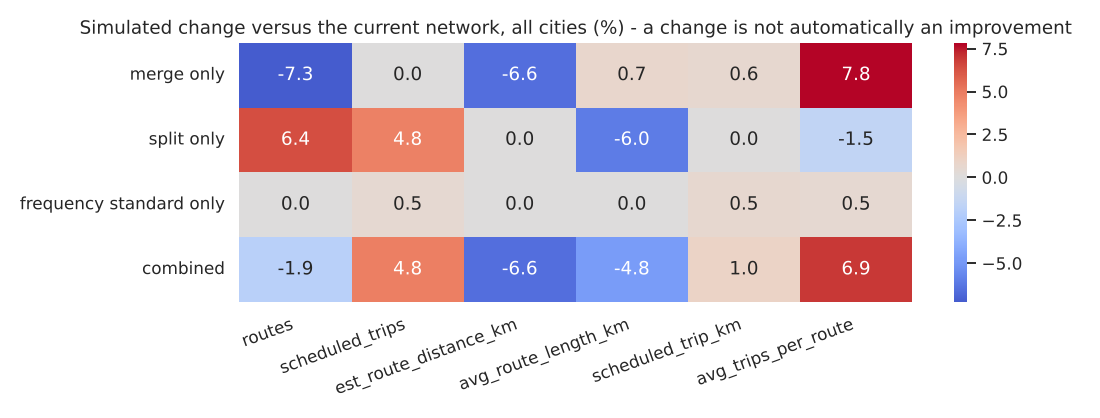

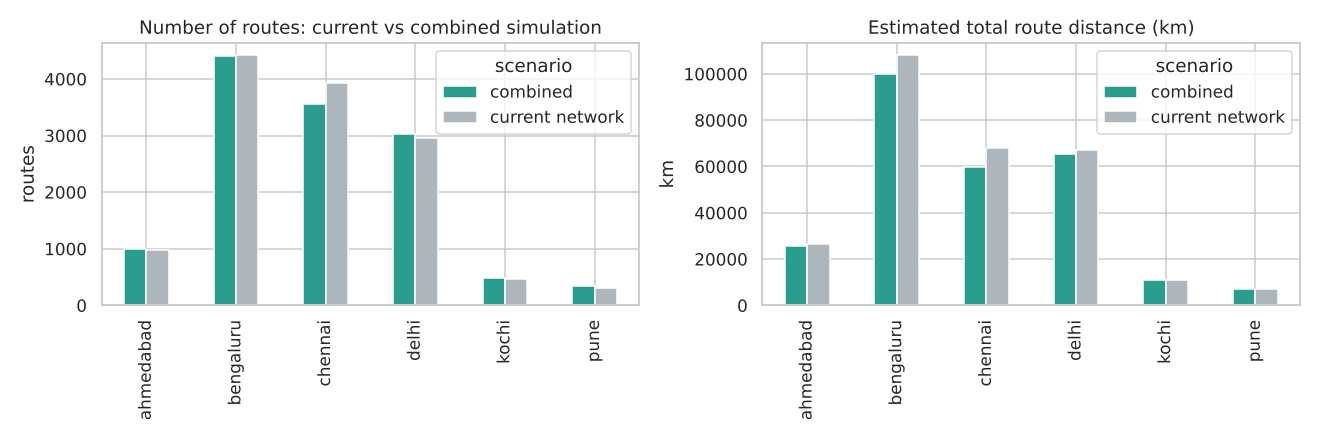

In [16]:
display(Image("reports/figures/module6/m6_05_current_vs_simulated_total.png"))
display(Image("reports/figures/module6/m6_06_current_vs_simulated_by_city.png"))

## Step 9 – Save the deliverables
The runner writes the predictions, the simulated network, tables, figures and the three reports (same logic as above).

In [17]:
import run_module6
run_module6.main()
sorted(os.listdir("data/inference")), sorted(os.listdir("data/simulated"))

done | inference check diff 8.9e-16 | roles {'train (seen by the models)': 10466, 'unseen feed (not in Module-4 training set)': 1031, 'validation (unseen routes)': 2600} | new-feed noise 81.7% | candidates >=2 flags 3939 (>=3: 863) | merges 949 splits 838 freq 1098 | routes 13066 -> 12815


(['inference_predictions.csv', 'unseen_routes.csv'], ['simulated_network.csv'])

## Limitations
* Scheduled data only – no ridership, capacity, delays or cost. Suggestions are candidates; every one lists what must be verified first.
* Overlap is stop-based and lengths are often straight-line lower bounds; shapes were not used for the suggestions.
* Thresholds (80% overlap, 25th percentile, 40 km, 30 stops, 30-minute standard) are stated rules of thumb and change the counts.
* Hyderabad is excluded (not comparable); Delhi, Kochi and Pune have near-constant scheduled speeds; in uniform feeds such as Kochi no route is 'lightly scheduled' relative to its peers, so no merges arise there.
* The simulation shows what the assumptions do to the *schedule*, not to passengers.

**Next module (7):** a Streamlit dashboard to upload GTFS files, view clusters, predictions and scenarios.